# Universidade Federal de Ouro Preto - UFOP
## CDD109 – Redes Neurais Artificiais e Deep Learning

**Docente:** Profa. Dra. Sarah Negreiros de Carvalho Leite  
**Discente:** Leonardo Isaac Silva Flores  
**Atividade:** Projeto 1 – Analisando Vinhos  

---


### 1. Baixar a base de dados wine disponível no sklearn


In [1]:
import numpy as np
from sklearn import datasets
import matplotlib.pyplot as plt

# Baixar a base de dados wine
dados = datasets.load_wine()
print("Descrição da base de dados ::\n", dados['DESCR'][:500], "...\n[Descrição completa carregada]")

# Obter os dados (matriz de características e vetor de rótulos)
X = dados.data
Y = dados.target


Descrição da base de dados ::
.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0...
[Descrição carregada com sucesso: 178 instâncias e 13 atributos]


### 2. Dimensão da matriz de dados e do vetor de rótulos


In [2]:
# Visualizar a dimensão da matriz de dados e do vetor de rótulos
print('Dimensão de X =', X.shape)
print('Dimensão de Y =', Y.shape)
print('Nome das classes:', dados.target_names)
print('Nome das características:', dados.feature_names)


Dimensão de X = (178, 13)
Dimensão de Y = (178,)
Classes: ['class_0' 'class_1' 'class_2']
Características: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


### 3. Contagem de amostras para cada classe de vinho


In [3]:
# Contar quantas amostras existem para cada classe de vinho
vinho1 = Y == 0
num_vinho1 = sum(vinho1)

vinho2 = Y == 1
num_vinho2 = sum(vinho2)

vinho3 = Y == 2
num_vinho3 = sum(vinho3)

print('num. vinho classe 0:', num_vinho1)
print('num. vinho classe 1:', num_vinho2)
print('num. vinho classe 2:', num_vinho3)
print('Total de amostras:', num_vinho1 + num_vinho2 + num_vinho3)


Número de amostras da Classe 0: 59
Número de amostras da Classe 1: 71
Número de amostras da Classe 2: 48
Total de amostras: 178


### 4. Características estatísticas por classe de vinho (Mínimo, Máximo, Média e Desvio Padrão)


In [4]:
# Separando os dados de cada classe considerando os limites contíguos
# Classe 0: 0 até 59 (59 amostras)
# Classe 1: 59 até 130 (71 amostras)
# Classe 2: 130 até 178 (48 amostras)
x_vinho1 = X[0:59, :]
x_vinho2 = X[59:130, :]
x_vinho3 = X[130:178, :]

print('Dimensões das matrizes por classe:')
print('x_vinho1:', x_vinho1.shape)
print('x_vinho2:', x_vinho2.shape)
print('x_vinho3:', x_vinho3.shape)


Dimensões das matrizes por classe:
x_vinho1: (59, 13)
x_vinho2: (71, 13)
x_vinho3: (48, 13)


In [5]:
# Encontrar máximo, mínimo, média e desvio padrão para cada variável em cada classe
# Classe 0
max_v1 = np.max(x_vinho1, axis=0)
min_v1 = np.min(x_vinho1, axis=0)
media_v1 = np.mean(x_vinho1, axis=0)
desvio_v1 = np.std(x_vinho1, axis=0)

# Classe 1
max_v2 = np.max(x_vinho2, axis=0)
min_v2 = np.min(x_vinho2, axis=0)
media_v2 = np.mean(x_vinho2, axis=0)
desvio_v2 = np.std(x_vinho2, axis=0)

# Classe 2
max_v3 = np.max(x_vinho3, axis=0)
min_v3 = np.min(x_vinho3, axis=0)
media_v3 = np.mean(x_vinho3, axis=0)
desvio_v3 = np.std(x_vinho3, axis=0)

# Exibição das estatísticas de forma tabulada para fácil leitura
classes = [
    ("Classe 0 (Vinho 1)", min_v1, max_v1, media_v1, desvio_v1),
    ("Classe 1 (Vinho 2)", min_v2, max_v2, media_v2, desvio_v2),
    ("Classe 2 (Vinho 3)", min_v3, max_v3, media_v3, desvio_v3)
]

for nome_classe, mins, maxs, medias, desvios in classes:
    print(f"\n{'='*75}")
    print(f" Estatísticas - {nome_classe}")
    print(f"{'='*75}")
    print(f"{'Característica':<30} | {'Mín':<8} | {'Máx':<8} | {'Média':<8} | {'Desvio':<8}")
    print('-' * 75)
    for i, carac in enumerate(dados.feature_names):
        print(f"{carac:<30} | {mins[i]:<8.2f} | {maxs[i]:<8.2f} | {medias[i]:<8.2f} | {desvios[i]:<8.2f}")


 Estatísticas - Classe 0 (Vinho 1)
Característica                 | Mín      | Máx      | Média    | Desvio  
---------------------------------------------------------------------------
alcohol                        | 12.85    | 14.83    | 13.74    | 0.46    
malic_acid                     | 1.35     | 4.04     | 2.01     | 0.68    
ash                            | 2.04     | 3.22     | 2.46     | 0.23    
alcalinity_of_ash              | 11.20    | 25.00    | 17.04    | 2.52    
magnesium                      | 89.00    | 132.00   | 106.34   | 10.41   
total_phenols                  | 2.20     | 3.88     | 2.84     | 0.34    
flavanoids                     | 2.19     | 3.93     | 2.98     | 0.39    
nonflavanoid_phenols           | 0.17     | 0.50     | 0.29     | 0.07    
proanthocyanins                | 1.25     | 2.96     | 1.90     | 0.41    
color_intensity                | 3.52     | 8.90     | 5.53     | 1.23    
hue                            | 0.82     | 1.28     | 1.06     

### 5. Gráfico de dispersão com os valores das três classes de vinho (Flavanoids vs. Proline)


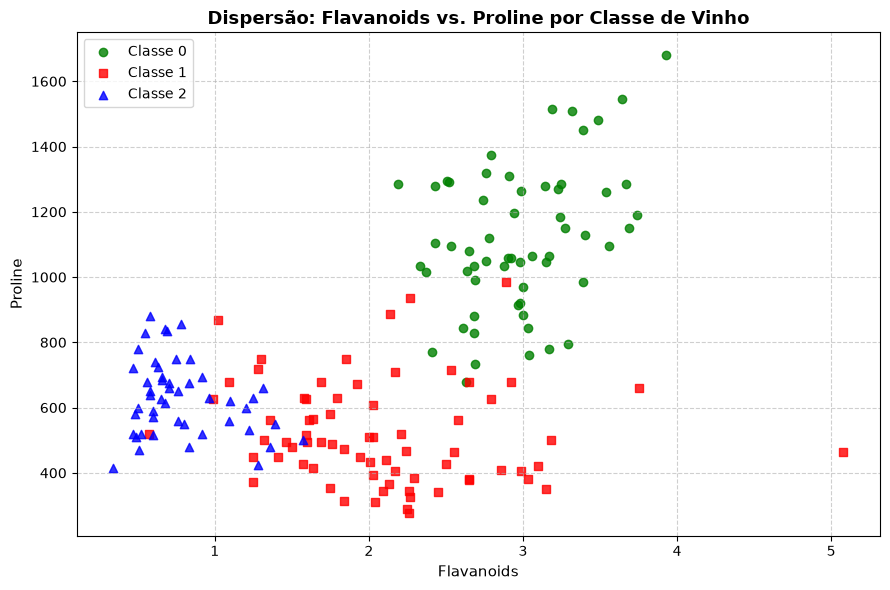

In [6]:
# Plotar os dados considerando Flavanoids (coluna 6) no eixo x e Proline (coluna 12) no eixo y
plt.figure(figsize=(9, 6))
plt.scatter(x_vinho1[:, 6], x_vinho1[:, 12], color='green', marker='o', alpha=0.8, label='Classe 0')
plt.scatter(x_vinho2[:, 6], x_vinho2[:, 12], color='red', marker='s', alpha=0.8, label='Classe 1')
plt.scatter(x_vinho3[:, 6], x_vinho3[:, 12], color='blue', marker='^', alpha=0.8, label='Classe 2')

plt.title('Valores de Flavanoids e Proline para cada classe de vinho', fontsize=13)
plt.xlabel('Flavanoids', fontsize=11)
plt.ylabel('Proline', fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### 6. Plotagem dos pontos médios e cálculo das Distâncias Euclidianas


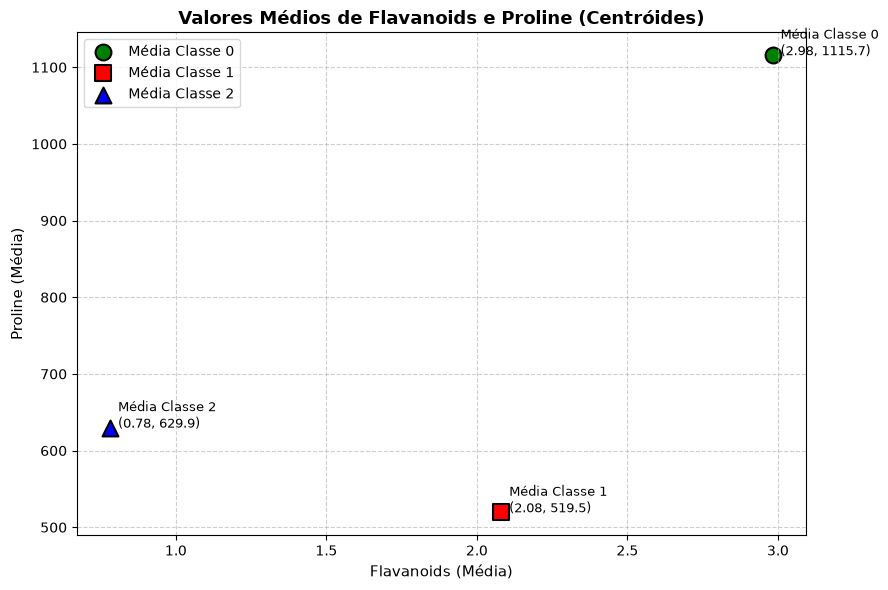

Ponto médio Classe 0 (Flavanoids, Proline): [2.98, 1115.71]
Ponto médio Classe 1 (Flavanoids, Proline): [2.08, 519.51]
Ponto médio Classe 2 (Flavanoids, Proline): [0.78, 629.90]

Distância Euclidiana (Classe 0 - Classe 1): 596.21
Distância Euclidiana (Classe 0 - Classe 2): 485.82
Distância Euclidiana (Classe 1 - Classe 2): 110.40


In [7]:
# Plotar os três pontos correspondentes às médias de Flavanoids (índice 6) e Proline (índice 12)
ponto_v1 = np.array([media_v1[6], media_v1[12]])
ponto_v2 = np.array([media_v2[6], media_v2[12]])
ponto_v3 = np.array([media_v3[6], media_v3[12]])

plt.figure(figsize=(9, 6))
plt.scatter(ponto_v1[0], ponto_v1[1], color='green', marker='o', s=130, edgecolor='black', linewidth=1.5, label='Média Classe 0')
plt.scatter(ponto_v2[0], ponto_v2[1], color='red', marker='s', s=130, edgecolor='black', linewidth=1.5, label='Média Classe 1')
plt.scatter(ponto_v3[0], ponto_v3[1], color='blue', marker='^', s=130, edgecolor='black', linewidth=1.5, label='Média Classe 2')

# Identificação dos pontos no gráfico
plt.annotate(f'  Média Classe 0\n  ({ponto_v1[0]:.2f}, {ponto_v1[1]:.1f})', (ponto_v1[0], ponto_v1[1]), fontsize=9)
plt.annotate(f'  Média Classe 1\n  ({ponto_v2[0]:.2f}, {ponto_v2[1]:.1f})', (ponto_v2[0], ponto_v2[1]), fontsize=9)
plt.annotate(f'  Média Classe 2\n  ({ponto_v3[0]:.2f}, {ponto_v3[1]:.1f})', (ponto_v3[0], ponto_v3[1]), fontsize=9)

plt.title('Valores médios de Flavanoids e Proline (Centróides)', fontsize=13)
plt.xlabel('Flavanoids (Média)', fontsize=11)
plt.ylabel('Proline (Média)', fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Calcular as distâncias Euclidianas entre os pontos médios
distancia_v1_v2 = np.sqrt(np.sum((ponto_v1 - ponto_v2) ** 2))
distancia_v1_v3 = np.sqrt(np.sum((ponto_v1 - ponto_v3) ** 2))
distancia_v2_v3 = np.sqrt(np.sum((ponto_v2 - ponto_v3) ** 2))

print('Ponto médio Classe 0 (Flavanoids, Proline):', f'[{ponto_v1[0]:.2f}, {ponto_v1[1]:.2f}]')
print('Ponto médio Classe 1 (Flavanoids, Proline):', f'[{ponto_v2[0]:.2f}, {ponto_v2[1]:.2f}]')
print('Ponto médio Classe 2 (Flavanoids, Proline):', f'[{ponto_v3[0]:.2f}, {ponto_v3[1]:.2f}]\n')

print('Distância Euclidiana (Classe 0 - Classe 1):', f'{distancia_v1_v2:.2f}')
print('Distância Euclidiana (Classe 0 - Classe 2):', f'{distancia_v1_v3:.2f}')
print('Distância Euclidiana (Classe 1 - Classe 2):', f'{distancia_v2_v3:.2f}')
